# 04 — Imagination 롤아웃과 이슈 발굴

여기서부터가 "모델을 업데이트하거나 이슈를 발굴하는" 실무에 제일 가까운 부분입니다.

절차:
1. 에피소드의 처음 `CONTEXT` 스텝은 실제 관측으로 `posterior_step`을 돌려서 은닉 상태를
   "워밍업"합니다 (모델이 지금 상황을 인식하게 함).
2. 그 다음부터는 **진짜 프레임을 더 이상 보여주지 않고**, `prior_step`만으로 끝까지 굴립니다
   (action은 실제 에피소드의 action을 그대로 넣어줍니다 — planner는 이 프로젝트 범위 밖이므로,
   "world model이 주어진 action 시퀀스 하의 미래를 얼마나 잘 상상하는가"만 봅니다).
3. 매 스텝 상상한 이미지와 실제 이미지의 차이(MSE)를 기록해서, **오차가 시간에 따라
   어떻게 누적되는지** 그래프로 봅니다.


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import wm_toy as W

device = "cuda" if torch.cuda.is_available() else "cpu"
model = W.WorldModel().to(device)
model.load_state_dict(torch.load("checkpoints/world_model.pt", map_location=device))
model.eval()

val_ds = W.WMSequenceDataset(num_episodes=8, T=40, base_seed=9000)
frames, actions, states = val_ds[2]
frames, actions = frames.unsqueeze(0).to(device), actions.unsqueeze(0).to(device)
T = frames.shape[1]
CONTEXT = 8

mse = torch.nn.MSELoss(reduction="mean")
h = model.init_hidden(1, device)
imagined, per_step_error = [], []

with torch.no_grad():
    for t in range(T):
        if t < CONTEXT:
            h, recon, _ = model.posterior_step(h, frames[:, t], actions[:, t])
        else:
            h, recon, _ = model.prior_step(h, actions[:, t])
        imagined.append(recon[0].cpu().numpy())
        per_step_error.append(float(mse(recon, frames[:, t])))

print("rollout done. context steps:", CONTEXT, "/ total steps:", T)


rollout done. context steps: 8 / total steps: 40


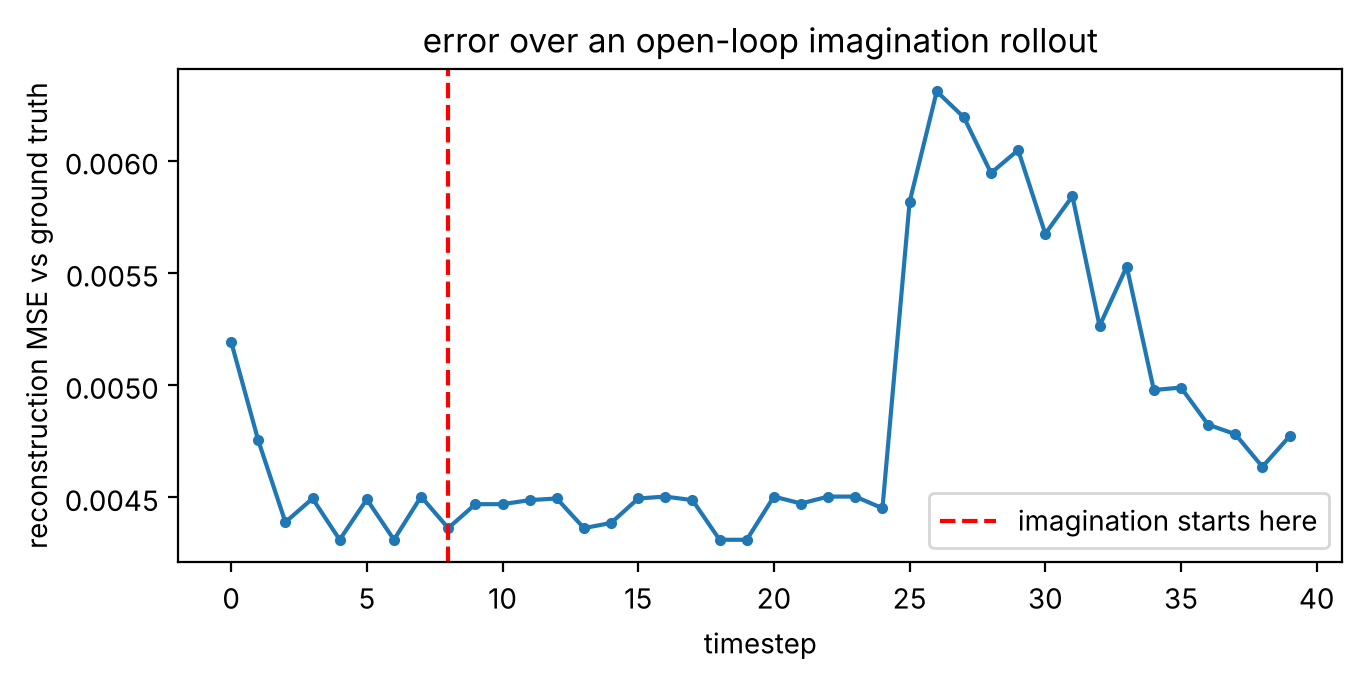

In [2]:
plt.figure(figsize=(7, 3.5))
plt.plot(per_step_error, marker="o", ms=3)
plt.axvline(CONTEXT, color="red", linestyle="--", label="imagination starts here")
plt.xlabel("timestep"); plt.ylabel("reconstruction MSE vs ground truth")
plt.title("error over an open-loop imagination rollout")
plt.legend(); plt.tight_layout(); plt.show()


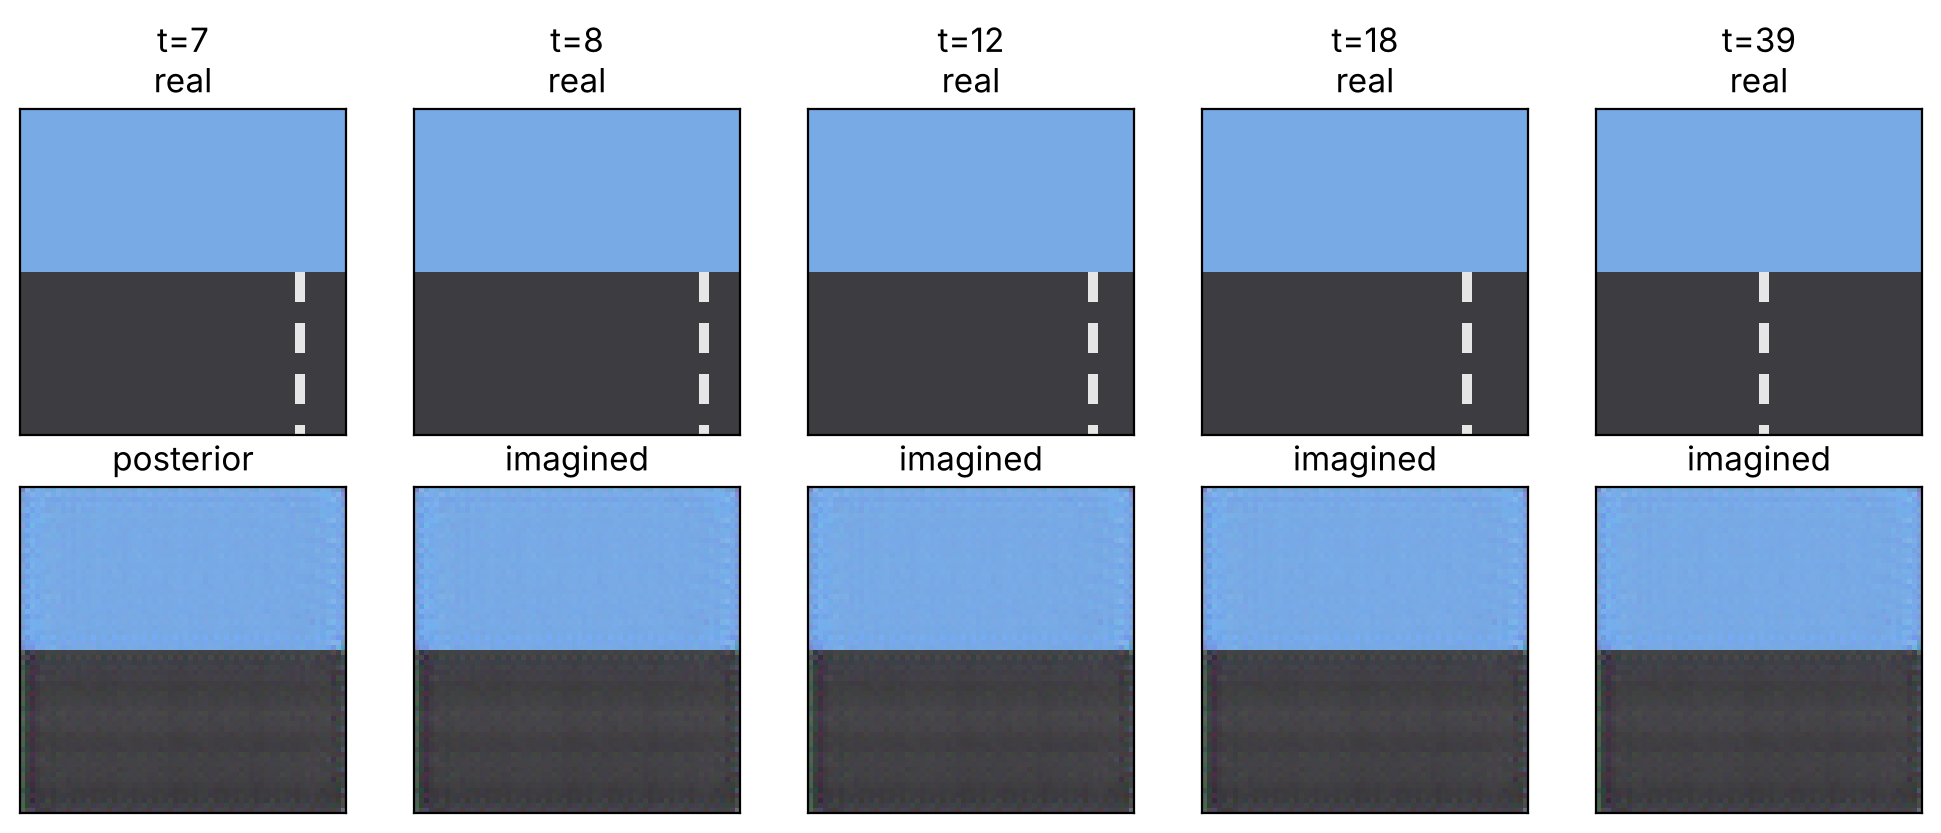

In [3]:
timesteps = [CONTEXT - 1, CONTEXT, CONTEXT + 4, CONTEXT + 10, T - 1]
fig, axes = plt.subplots(2, len(timesteps), figsize=(len(timesteps) * 2.0, 4.2))
for col, t in enumerate(timesteps):
    axes[0, col].imshow(W.frame_to_uint8(frames[0, t, 0].cpu().numpy()))
    axes[0, col].set_title(f"t={t}\nreal")
    axes[1, col].imshow(W.frame_to_uint8(imagined[t][0]))
    tag = "posterior" if t < CONTEXT else "imagined"
    axes[1, col].set_title(tag)
    for r in range(2):
        axes[r, col].set_xticks([]); axes[r, col].set_yticks([])
plt.tight_layout(); plt.show()


## 이슈 리포트 — 곡선 모양을 "읽는" 법

여기서 중요한 건 미리 정해진 정답 그래프가 아니라, **당신이 방금 실행한 오차 곡선이 실제로
어떤 모양인지를 먼저 보고, 그에 맞는 가설을 세우는 것**입니다. `CONTEXT`, `base_seed`,
에피소드 인덱스(`val_ds[2]`)를 바꿔가며 여러 번 돌려보면 대체로 아래 셋 중 하나(또는 섞인
형태)를 보게 됩니다.

**(A) 상상 시작 이후 오차가 계속 커진다 (단조 증가)**
→ 전형적인 *exposure bias / compounding error*입니다. 학습 때는 매 스텝 실제 관측으로
보정(teacher forcing)되지만, 상상 단계는 자기 예측을 반복 입력하므로 작은 오차가 계속
누적됩니다. 결정론적 `embed_head`가 여러 가능한 미래를 평균내 버리는 것도 한몫합니다.

**(B) 중간에 한 번 튀었다가 다시 가라앉는다**
→ 특정 구간(예: 앞차가 끼어들거나 ego가 차선을 바꾸는 시점)에서만 일시적으로 예측이
어긋나고, 그 뒤엔 다시 "평균적인 장면"으로 안정화되는 경우입니다. 이건 모델이 복잡한
이벤트는 잘 못 맞히지만 단조로운 구간은 그럭저럭 따라간다는 뜻이고, 어느 타임스텝에서
튀었는지를 그 시점의 실제 state(`states` 배열 — 차선 변경 여부, 앞차 거리)와 대조해보면
"어떤 상황에서 약한지"를 구체적으로 짚어낼 수 있습니다.

**(C) 거의 평평하다 (오차가 거의 안 늘어난다)**
→ 얼핏 좋아 보이지만, 의심해봐야 합니다: 이 toy 세계가 너무 단순해서 (차선 변화가 느리고
예측 가능해서) 모델이 딱히 어려운 걸 "상상"할 필요가 없었을 수 있습니다. 실제로는 "world
model이 뛰어나다"가 아니라 "task가 너무 쉬웠다"는 이슈일 수 있다는 뜻 — 실무에서도 흔한
함정입니다 (쉬운 평가셋에서 좋아 보이는 모델).

**공통 다음 실험 후보 (어떤 패턴이었든 시도해볼 만함)**:
- `embed_head`를 결정론적 벡터 대신 가우시안 분포(평균+분산)로 바꾸고 KL 정규화를 추가
  (RSSM/Dreamer 쪽에서 쓰는 방식) — (A)처럼 흐려지는 문제에 직접 효과적.
- 학습 때도 가끔 `prior_step`으로 몇 스텝 굴려본 뒤 loss를 주는 **scheduled sampling**을
  적용해서, "자기 예측을 입력으로 받는 상황"에 미리 적응시키기.
- `CONTEXT` 길이나 시뮬레이터의 `target_change_every`(차선 변경 빈도)를 조절해서 task
  난이도 자체를 바꿔보고 곡선이 어떻게 바뀌는지 비교 — (C)가 의심될 때 특히 유용.
- 픽셀 재구성 손실 대신(혹은 더해서) 저차원 상태(`states`, 예: 앞차와의 거리)에 대한 보조
  손실을 추가해서, "그림은 흐려져도 핵심 수치는 맞는지"를 따로 측정.

이렇게 **정량 지표(오차 곡선) + 정성 관찰(이미지) + 원인 가설 + 다음 실험**을 묶어서
기록하는 루틴 자체가, 실제로 큰 모델을 맡아 "뭐가 문제인지 찾아내는" 일의 축소판입니다.
